In [4]:
using IonSim
using QuantumOptics
using PyPlot
using LinearAlgebra

In [5]:
function laguerre(n::Int, x::Float64)
    if n == 0 return 1.0 end
    if n == 1 return 1.0 - x end
    L_prev2 = 1.0
    L_prev1 = 1.0 - x
    L_curr = 0.0
    for k in 1:(n-1)
        L_curr = ((2k + 1 - x) * L_prev1 - k * L_prev2) / (k + 1)
        L_prev2 = L_prev1
        L_prev1 = L_curr
    end
    return L_curr
end

laguerre (generic function with 1 method)

In [6]:
function calculate_qcrb(state, state_perturbed, d_alpha::Float64; tol=1e-10)
    
    # 1. Promote pure states (Ket) to density matrices
    rho1 = isa(state, Ket) ? dm(state) : state
    rho2 = isa(state_perturbed, Ket) ? dm(state_perturbed) : state_perturbed
    
    # 2. Extract dense data
    rho_dense_data = dense(rho1).data
    rho_pert_dense_data = dense(rho2).data

    # 3. Finite difference derivative
    drho_data = (rho_pert_dense_data - rho_dense_data) / d_alpha
    
    # 4. Use Hermitian() to guarantee real eigenvalues and speed up diagonalization
    λ, V = LinearAlgebra.eigen(Hermitian(rho_dense_data))
    
    qfi = 0.0
    n = length(λ)
    
    for i in 1:n
        for j in 1:n
            if real(λ[i] + λ[j]) > tol
                # 5. Use @views to prevent memory allocation during column slicing
                @views v_i = V[:, i]
                @views v_j = V[:, j]
                
                drho_ij = dot(v_i, drho_data * v_j)
                qfi += 2 * (abs(drho_ij)^2) / real(λ[i] + λ[j])
            end
        end
    end
    
    qcrb = qfi > 0 ? 1.0 / qfi : Inf
    return qfi, qcrb
end

calculate_qcrb (generic function with 1 method)

In [8]:
function SDF_apply_with_alpha(laser_intensity = 1e4, angle = 0, target_alpha = 0.716, cat_state = false, initial_state = nothing, fock_state_n = 0, n_th_set = 10000.0, gamma_0_set = 1e-2)

    # ---------------------------------------------------------
    # 1. Common Trap InitializationQ
    # ---------------------------------------------------------
    trap_freq = 19e5 
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))

    mode_z = zmodes(chain)[1] 
    mode_z.N = 50
    mode_z.shape = [51]

    k_vec = (x̂ + ẑ) / √2
    ϵ_vec = ŷ
    B_field = 1e-13
    
    trap_pre = Chamber(iontrap=chain, B=B_field, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    mode = zmodes(trap_pre)[1]

    ψ_ion = normalize(ion["g"])
    ψ_mode = fockstate(mode, fock_state_n)
    
    ψ_initial = initial_state !== nothing ? initial_state : (ψ_ion ⊗ ψ_mode)

    # ---------------------------------------------------------
    # 2. Physics Calculation
    # ---------------------------------------------------------
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_total = 2 * π / transition_λ
    k_z = k_total / sqrt(2)
    eta = k_z * z_zpf

    dummy_laser = Laser(I=laser_intensity, k=k_vec, ϵ=ϵ_vec, λ=transition_λ)
    Bhat_tuple = (; x=0.0, y=0.0, z=1.0)
    
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), Bhat_tuple)
    Omega_eff = Omega_eff_Hz * 2 * π

    # ---------------------------------------------------------
    # 3. SEQUENCE EXECUTION
    # ---------------------------------------------------------
    if cat_state
        # =========================================================
        # PERFECT OPERATOR MATH: Alpha Readout (No readout noise)
        # =========================================================
        alpha_complex = target_alpha * exp(1im * angle)
        g = ion["g"]
        e = ion["e"]
        
        x_plus = normalize(g + e)
        x_minus = normalize(g - e)
        
        P_plus = x_plus ⊗ dagger(x_plus)
        P_minus = x_minus ⊗ dagger(x_minus)
        
        D_plus = IonSim.displace(mode, alpha_complex)
        D_minus = IonSim.displace(mode, -alpha_complex)
        
        U_SDF = (P_plus ⊗ D_plus) + (P_minus ⊗ D_minus)
        
        if isa(ψ_initial, Operator)
            return U_SDF * ψ_initial * dagger(U_SDF)
        else
            return U_SDF * ψ_initial
        end
        
    else
        # =========================================================
        # CONTINUOUS LINDBLAD DISPLACEMENT: Beta Signal (With Noise)
        # =========================================================
        I_spin = identityoperator(ion["g"].basis)  
        n_th = n_th_set           
        gamma_0 = gamma_0_set  
    
        gamma_plus_us = (gamma_0 * n_th) * 1e-6 
        gamma_minus_us = (gamma_0 * (n_th + 1)) * 1e-6 

        temp_fock_basis = FockBasis(mode.N) 
        a_op = DenseOperator(mode, mode, QuantumOptics.destroy(temp_fock_basis).data)
        at_op = DenseOperator(mode, mode, QuantumOptics.create(temp_fock_basis).data)

        # CRITICAL FIX: Lock the simulation time to the beta=1.0 baseline.
        # This guarantees identical ODE grid steps for finite difference.
        baseline_beta = 1.0 
        target_time_s = (2 * baseline_beta) / (eta * Omega_eff)
        target_time_us = target_time_s * 1e6

        # The target_alpha (beta + d_beta) now scales the Hamiltonian amplitude!
        H_m = (1im * target_alpha / target_time_us) * (exp(1im * angle) * at_op - exp(-1im * angle) * a_op)
        H_sys = I_spin ⊗ H_m

        a_sys = I_spin ⊗ a_op
        at_sys = I_spin ⊗ at_op

        J_cool = sqrt(gamma_minus_us) * a_sys
        J_heat = sqrt(gamma_plus_us) * at_sys
        J_ops = [J_cool, J_heat]
        J_ops_dag = dagger.(J_ops)

        function f_dyn(time_t, rho_state)
            return (H_sys, J_ops, J_ops_dag)
        end

        rho_initial = isa(ψ_initial, Ket) ? dm(ψ_initial) : ψ_initial
        
        # We only need the start and end points for the solver now
        tspan_sdf = [0.0, target_time_us]

        println("Simulating pure continuous Beta displacement with Lindblad noise...")
        # Added strict tolerances to completely eliminate numerical ODE phase drift
        _, sol_beta = timeevolution.master_dynamic(tspan_sdf, rho_initial, f_dyn, reltol=1e-10, abstol=1e-12)

        return sol_beta[end]
    end
end

SDF_apply_with_alpha (generic function with 9 methods)

In [9]:

function get_qcrb_coordinates(n_fock::Int=0, r_squeeze::Float64=0.0, laser_intensity::Float64=1e3, gamma_0::Float64=1e-2, n_th_set::Float64=1000.0)
    
    beta_signal = 1.0
    d_beta = 1e-4 
    
    trap_freq = 19e5 
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    B_field = 1e-13
    trap_pre = Chamber(iontrap=chain, B=B_field, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    
    sim_mode = zmodes(trap_pre)[1]
    sim_mode.N = 50
    sim_mode.shape = [51]
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_total = 2 * π / transition_λ
    k_z = k_total / sqrt(2)
    eta = k_z * z_zpf

    k_vec = (x̂ + ẑ) / √2
    ϵ_vec = ŷ
    dummy_laser = Laser(I=laser_intensity, k=k_vec, ϵ=ϵ_vec, λ=transition_λ)
    Bhat_tuple = (; x=0.0, y=0.0, z=1.0)
    
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), Bhat_tuple)
    Omega_eff = Omega_eff_Hz * 2 * π
    
    t_sig_s = (2 * beta_signal) / (eta * Omega_eff)
    t_sig_us = t_sig_s * 1e6
    
    println("==================================================")
    println(" EXACT TIME CALCULATION")
    println("==================================================")
    println(" Signal Magnitude (β): ", beta_signal)
    println(" Exposure Time (t)   : ", round(t_sig_us, digits=2), " μs")
    println(" Base Gamma Rate     : ", gamma_0)
    println(" Thermal Phonons (n) : ", n_th_set)
    println("==================================================")

    b_fock = FockBasis(50) 
    vac_qo = fockstate(b_fock, n_fock)
    
    if r_squeeze > 0.0
        squeeze_op = squeeze(b_fock, r_squeeze * exp(1im * 0.0))
        initial_m_qo = squeeze_op * vac_qo
    else
        initial_m_qo = vac_qo
    end
    
    initial_m_sim = Ket(sim_mode, initial_m_qo.data)
    initial_sys = normalize(ion["g"]) ⊗ initial_m_sim

    println("\nRunning master equation for Base β Signal...")
    # Passed gamma_0 into the generator
    noisy_beta_state = SDF_apply_with_alpha(laser_intensity, 0.0, beta_signal, false, initial_sys, n_fock, n_th_set, gamma_0)
    
    println("\nRunning master equation for Perturbed β Signal (+ d_beta)...")
    # Passed gamma_0 into the generator
    noisy_beta_state_pert = SDF_apply_with_alpha(laser_intensity, 0.0, beta_signal + d_beta, false, initial_sys, n_fock, n_th_set, gamma_0)

    alphas = collect(0.1:0.1:1.6)
    sim_qcrbs = Float64[]
    theory_thermal_qcrbs = Float64[]
    theory_closed_qcrbs = Float64[]
    theory_nolaser_qcrbs = Float64[]

    Gamma_t = (gamma_0 * 1e-6) * t_sig_us

    println("\nSweeping α readout (generating coordinates)...")
    for a in alphas
        # Passed gamma_0 into the readout
        state_a_full = SDF_apply_with_alpha(laser_intensity, pi/2, a, true, noisy_beta_state, n_fock, n_th_set, gamma_0)
        state_a_pert_full = SDF_apply_with_alpha(laser_intensity, pi/2, a, true, noisy_beta_state_pert, n_fock, n_th_set, gamma_0)

        rho_spin_a = ptrace(state_a_full, 2)
        rho_spin_a_pert = ptrace(state_a_pert_full, 2)
        
        _, qcrb_sim = calculate_qcrb(rho_spin_a, rho_spin_a_pert, d_beta)
        push!(sim_qcrbs, qcrb_sim)

        # --- REVISED CONTINUOUS DRIVE THEORY ---
        # 1. Variance envelope (exponent) remains unchanged
        thermal_heating_factor = (2 * n_th_set) + 1.0
        exp_term_open = 4 * a^2 * (thermal_heating_factor * (1 - exp(-Gamma_t)) + exp(-Gamma_t - 2*r_squeeze))
        numerator_open = exp(exp_term_open)
        
        # 2. Laguerre term remains unchanged
        L_val_open = laguerre(n_fock, 4 * a^2 * exp(-Gamma_t - 2*r_squeeze))
        
        # 3. Continuous signal integration (safeguarded against Gamma_t = 0)
        continuous_signal_factor = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0
        
        # 4. Denominator applies the continuous signal factor instead of instantaneous exp(-Gamma_t)
        denominator_open = 16 * a^2 * (continuous_signal_factor^2) * (L_val_open^2)
        
        push!(theory_thermal_qcrbs, numerator_open / denominator_open)
        # ---------------------------------------

        exp_term_closed = 4 * a^2 * exp(-2*r_squeeze)
        numerator_closed = exp(exp_term_closed)
        
        L_val_closed = laguerre(n_fock, 4 * a^2 * exp(-2*r_squeeze))
        denominator_closed = 16 * a^2 * (L_val_closed^2)
        
        push!(theory_closed_qcrbs, numerator_closed / denominator_closed)

        thermal_heating_factor = (2 * n_th_set) + 1.0
        exp_term_open = 4 * a^2 * (thermal_heating_factor * (1 - exp(-Gamma_t)) + exp(-Gamma_t - 2*r_squeeze))
        numerator_open = exp(exp_term_open)
        
        L_val_open = laguerre(n_fock, 4 * a^2 * exp(-Gamma_t - 2*r_squeeze))
        denominator_open = 16 * a^2 * exp(-Gamma_t) * (L_val_open^2)
        
        push!(theory_nolaser_qcrbs, numerator_open / denominator_open)
    end

    return alphas, sim_qcrbs, theory_thermal_qcrbs, theory_closed_qcrbs, theory_nolaser_qcrbs
end

get_qcrb_coordinates (generic function with 6 methods)

In [10]:
function plot_qcrb_results(n_fock::Int=0, r_squeeze::Float64=0.0, laser_intensity::Float64=1e3, gamma_0::Float64=1e-2, n_th_set::Float64=1000.0)
    x_alpha, y_sim, y_theory_open, y_theory_closed, y_nolaser_drift = get_qcrb_coordinates(n_fock, r_squeeze, laser_intensity, gamma_0, n_th_set)

    # --- Recompute coupling rate g for the title ---
    trap_freq = 19e5 
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    B_field = 1e-13
    trap_pre = Chamber(iontrap=chain, B=B_field, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_z = (2 * π / transition_λ) / sqrt(2)
    eta = k_z * z_zpf

    k_vec = (x̂ + ẑ) / √2
    ϵ_vec = ŷ
    dummy_laser = Laser(I=laser_intensity, k=k_vec, ϵ=ϵ_vec, λ=transition_λ)
    Bhat_tuple = (; x=0.0, y=0.0, z=1.0)
    
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), Bhat_tuple)
    
    # Calculate coupling rate g (rad/s) and round for the title
    g_coupling = (eta * Omega_eff_Hz * 2 * π) / 2.0
    g_display = round(g_coupling, digits=2)
    # -----------------------------------------------

    fig = figure(figsize=(8, 6))
    
    plot(x_alpha, y_sim, "o", markersize=8, color="dodgerblue", label="Simulation (n_th = $(n_th_set))")
    plot(x_alpha, y_theory_open, "k--", linewidth=2.5, label="Theory (Eq. 65: Cold Bath)")
    plot(x_alpha, y_theory_closed, "r:", linewidth=2, label="Theory (Eq. 33: Closed System)")
    plot(x_alpha, y_nolaser_drift, "g-.", linewidth=2, label="Theory (Eq. 80: No Laser Drift)")

    yscale("log")
    xlabel("Readout Displacement [α]", fontsize=12)
    ylabel("QCRB (Ancilla Measurement Limit)", fontsize=12)
    
    # Updated title: dropped fontsize slightly to accommodate the longer string
    title("Fock = $(n_fock), r = $(r_squeeze), I = $(laser_intensity) (g = $(g_display)), gamma = $(gamma_0), n_th = $(n_th_set)", fontsize=11)
    
    legend(fontsize=11)
    grid(alpha=0.4)
    
    display(fig)
end

plot_qcrb_results (generic function with 6 methods)

 EXACT TIME CALCULATION
 Signal Magnitude (β): 1.0
 Exposure Time (t)   : 2206.67 μs
 Base Gamma Rate     : 100.0
 Thermal Phonons (n) : 0.0

Running master equation for Base β Signal...
Simulating pure continuous Beta displacement with Lindblad noise...

Running master equation for Perturbed β Signal (+ d_beta)...
Simulating pure continuous Beta displacement with Lindblad noise...

Sweeping α readout (generating coordinates)...


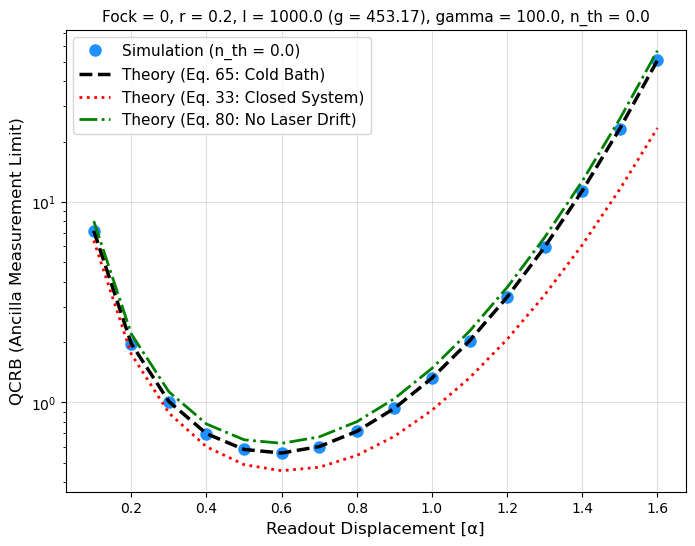

In [11]:
plot_qcrb_results(0, 0.2, 1e3, 1e2, 0.0)

In [12]:
using PyPlot

# -------------------------------------------------------------
# 1. Analytical QCRB Evaluator (from Eq. 65 / 74)
# -------------------------------------------------------------
function eval_qcrb_theory(a::Float64, n_fock::Int, r_squeeze::Float64, Gamma_t::Float64, n_th_set::Float64)
    thermal_factor = (2.0 * n_th_set) + 1.0
    B_var = thermal_factor * (1.0 - exp(-Gamma_t)) + exp(-Gamma_t - 2.0 * r_squeeze)
    
    numerator = exp(4.0 * a^2 * B_var)
    L_val = laguerre(n_fock, 4.0 * a^2 * exp(-Gamma_t - 2.0 * r_squeeze))
    
    continuous_signal = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0
    denominator = 16.0 * a^2 * (continuous_signal^2) * (L_val^2)
    
    return denominator <= 1e-14 ? Inf : numerator / denominator
end

# -------------------------------------------------------------
# 2. Solver for Optimal Alpha and Minimum QCRB
# -------------------------------------------------------------
function get_optimal_point(n_fock::Int, r_squeeze::Float64, Gamma_t::Float64, n_th_set::Float64)
    thermal_factor = (2.0 * n_th_set) + 1.0
    B_var = thermal_factor * (1.0 - exp(-Gamma_t)) + exp(-Gamma_t - 2.0 * r_squeeze)
    continuous_signal = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0

    # Exact closed-form solution for Fock n = 0
    if n_fock == 0
        opt_alpha = 1.0 / (2.0 * sqrt(B_var))
        min_qcrb = (exp(1.0) * B_var) / (4.0 * continuous_signal^2)
        return opt_alpha, min_qcrb
    end

    # DYNAMIC GRID: Scale the maximum alpha search bound by exp(r)
    # This guarantees the true global minimum is never cut off by the boundary.
    alpha_max = 2.5 * exp(r_squeeze)
    alpha_grid = range(0.05, stop=alpha_max, length=2000)
    
    best_qcrb = Inf
    best_alpha = 0.05

    for a in alpha_grid
        val = eval_qcrb_theory(a, n_fock, r_squeeze, Gamma_t, n_th_set)
        if val < best_qcrb
            best_qcrb = val
            best_alpha = a
        end
    end
    return best_alpha, best_qcrb
end

# -------------------------------------------------------------
# 3. Master Whiteboard Plotter
# -------------------------------------------------------------
function plot_whiteboard_analysis(laser_intensity::Float64=1e3, gamma_0::Float64=1e2, n_th_set::Float64=0.0)
    # Physical system constants (Ca40 trap setup)
    trap_freq = 19e5 
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    eta = (2 * π / transition_λ / sqrt(2)) * z_zpf

    dummy_laser = Laser(I=laser_intensity, k=(x̂ + ẑ)/√2, ϵ=ŷ, λ=transition_λ)
    Omega_eff = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0)) * 2 * π
    
    t_sig_us = ((2.0 * 1.0) / (eta * Omega_eff)) * 1e6
    Gamma_t = (gamma_0 * 1e-6) * t_sig_us

    # Grids for analysis
    r_vals = collect(0.0:0.02:1.0)
    n_vals = [0, 1, 2, 3]
    
    fig = figure(figsize=(16, 10))

    # --- Plot 1: min(QCRB) vs r ---
    subplot(2, 3, 1)
    for n in n_vals
        q_min = [get_optimal_point(n, r, Gamma_t, n_th_set)[2] for r in r_vals]
        plot(r_vals, q_min, linewidth=2, label="n = $n")
    end
    yscale("log")
    xlabel("Squeezing parameter [r]", fontsize=11)
    ylabel("min(QCRB)", fontsize=11)
    title("min(QCRB) vs r", fontsize=12)
    grid(alpha=0.3); legend()

    # --- Plot 2: min(QCRB) vs n ---
    subplot(2, 3, 2)
    r_targets = [0.0, 0.2, 0.5, 0.8]
    n_dense = 0:5
    for r in r_targets
        q_min_n = [get_optimal_point(n, r, Gamma_t, n_th_set)[2] for n in n_dense]
        plot(n_dense, q_min_n, "o--", linewidth=2, label="r = $r")
    end
    yscale("log")
    xlabel("Fock State [n]", fontsize=11)
    ylabel("min(QCRB)", fontsize=11)
    title("min(QCRB) vs n", fontsize=12)
    grid(alpha=0.3); legend()

    # --- Plot 3: opt α vs r ---
    subplot(2, 3, 4)
    for n in n_vals
        alpha_opt = [get_optimal_point(n, r, Gamma_t, n_th_set)[1] for r in r_vals]
        plot(r_vals, alpha_opt, linewidth=2, label="n = $n")
    end
    xlabel("Squeezing parameter [r]", fontsize=11)
    ylabel(L"\alpha_{opt}", fontsize=11)
    title(L"\alpha_{opt}\text{ vs r}", fontsize=12)
    grid(alpha=0.3); legend()

    # --- Plot 4: opt α vs n ---
    subplot(2, 3, 5)
    for r in r_targets
        alpha_opt_n = [get_optimal_point(n, r, Gamma_t, n_th_set)[1] for n in n_dense]
        plot(n_dense, alpha_opt_n, "s--", linewidth=2, label="r = $r")
    end
    xlabel("Fock State [n]", fontsize=11)
    ylabel(L"\alpha_{opt}", fontsize=11)
    title(L"\alpha_{opt}\text{ vs n}", fontsize=12)
    grid(alpha=0.3); legend()

    # --- Plot 5: min(QCRB) vs Decoherence Rate Γ ---
    subplot(1, 3, 3)
    gamma_sweep = 10.0 .^ range(0.0, 3.5, length=100)
    q_gamma = Float64[]
    for g_val in gamma_sweep
        gt_local = (g_val * 1e-6) * t_sig_us
        push!(q_gamma, get_optimal_point(0, 0.0, gt_local, n_th_set)[2])
    end
    plot(gamma_sweep, q_gamma, "r-", linewidth=2.5, label="r=0, n=0")
    xscale("log"); yscale("log")
    xlabel("Decoherence Rate Γ [s⁻¹]", fontsize=11)
    ylabel("min(QCRB)", fontsize=11)
    title(L"\text{Decoherence Scaling (r=0, n=0)}", fontsize=12)
    grid(alpha=0.3); legend()

    tight_layout()
    display(fig)
end

plot_whiteboard_analysis (generic function with 4 methods)

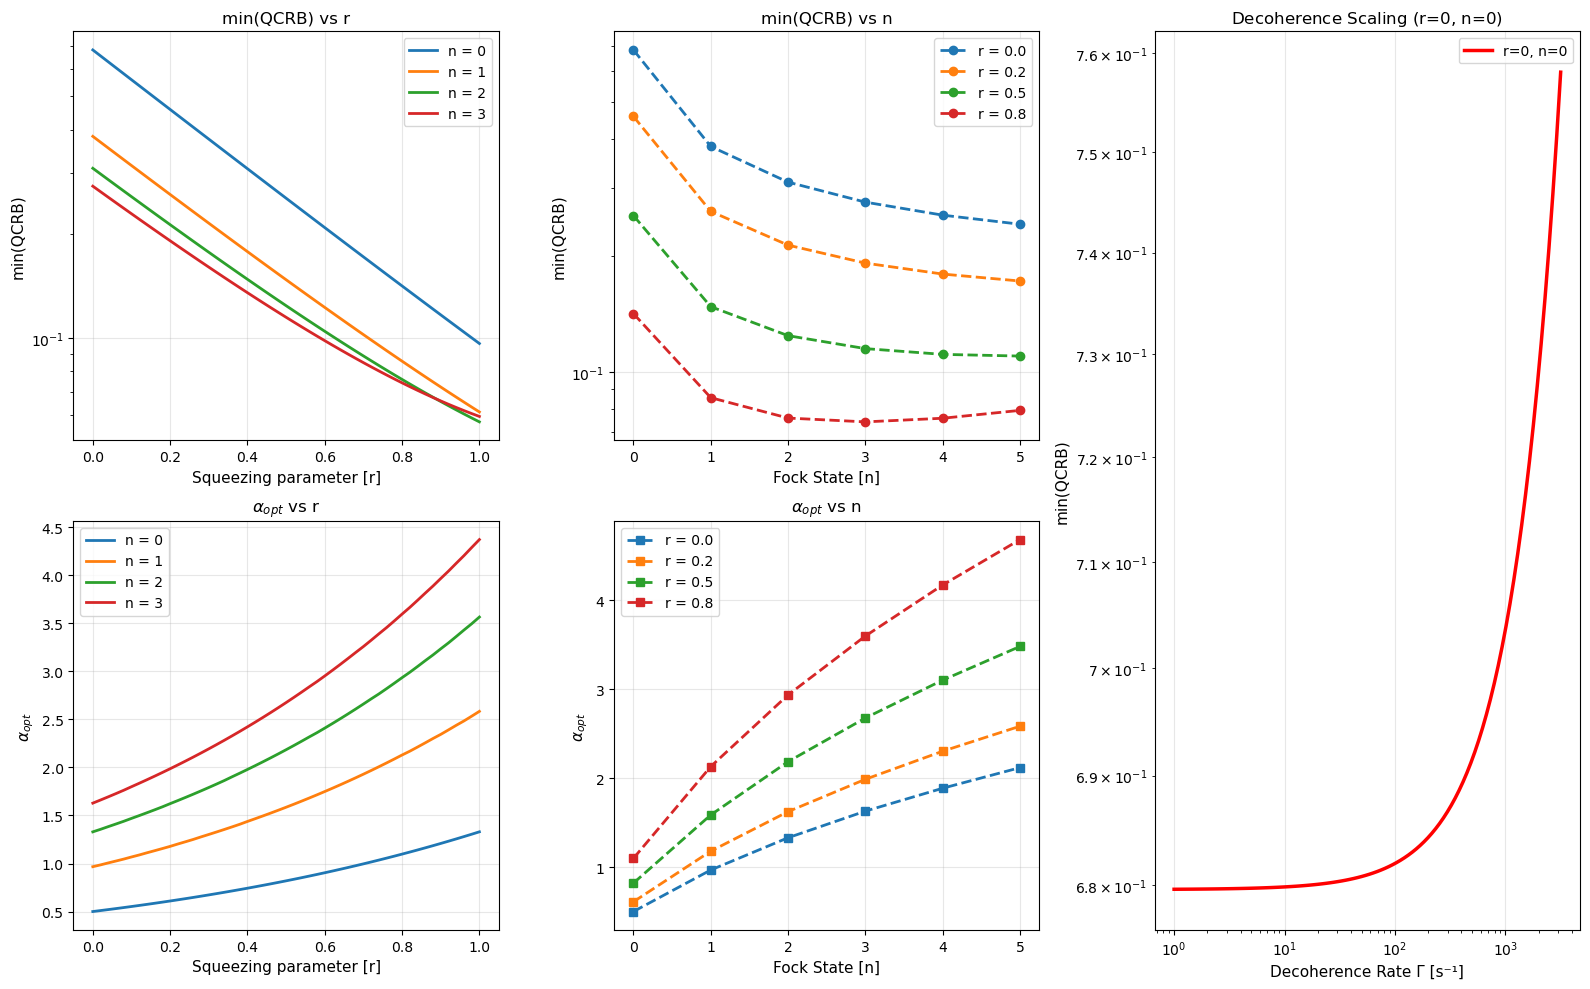

In [13]:
plot_whiteboard_analysis(1e6, 1e2, 0.0)

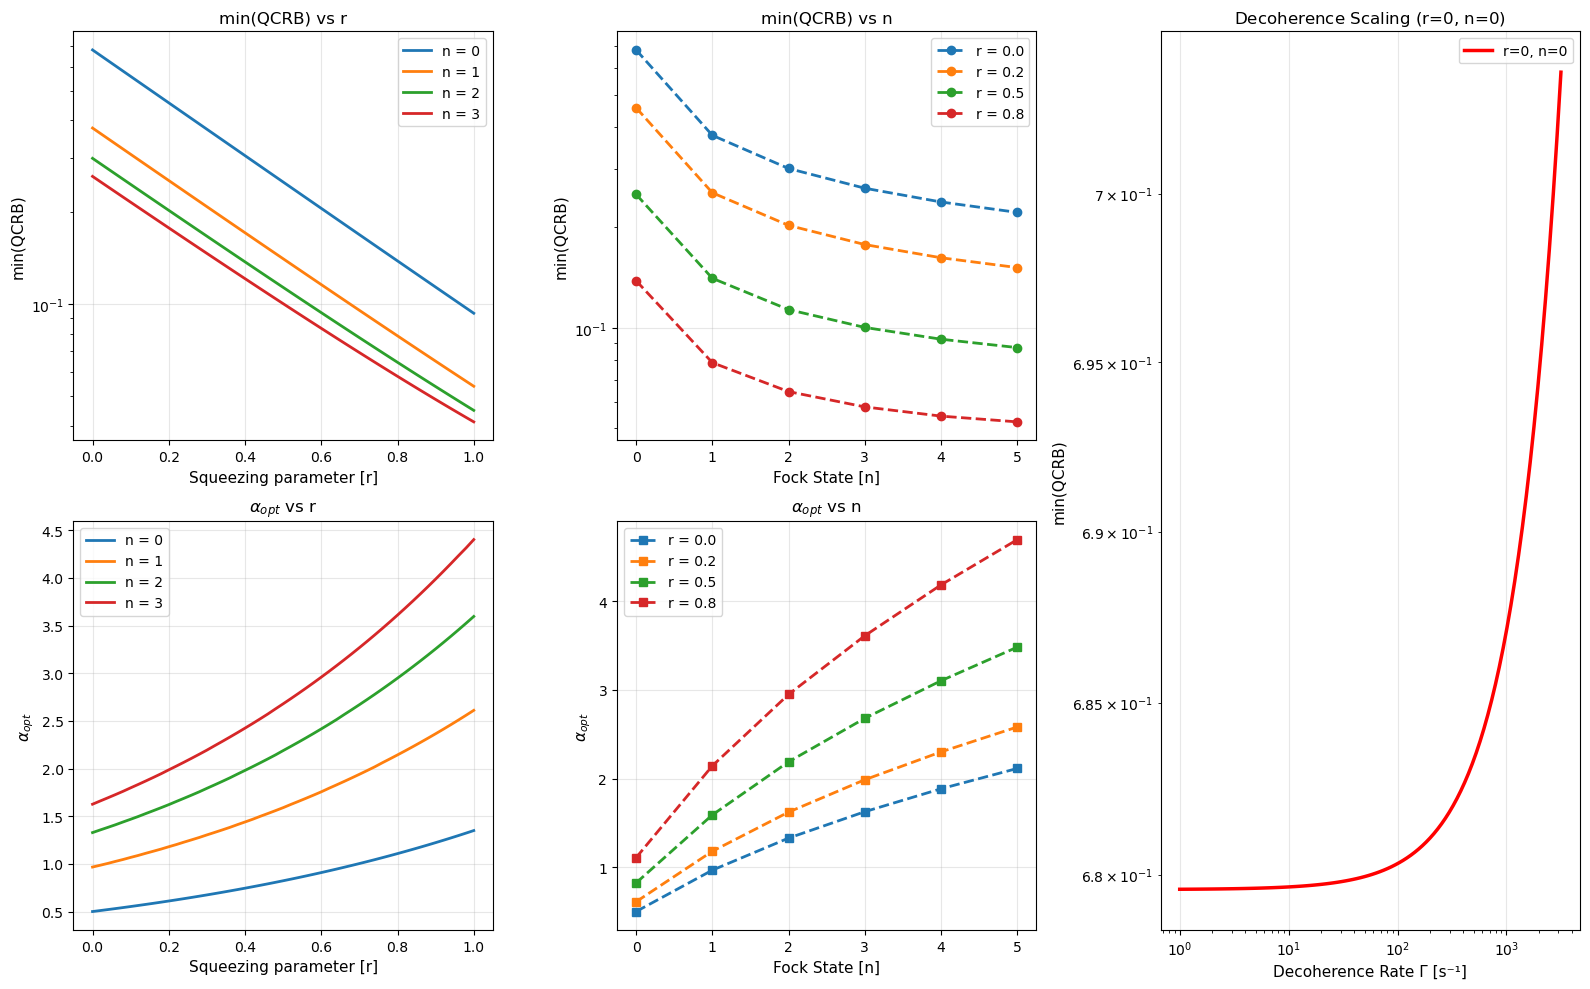

In [14]:
plot_whiteboard_analysis(1e7, 1e2, 0.0)

In [15]:
import Pkg;
Pkg.add("Roots")

   Resolving package versions...
     Project No packages added to or removed from `C:\Users\jewoo\projects\TestJulia\Project.toml`
    Manifest No packages added to or removed from `C:\Users\jewoo\projects\TestJulia\Manifest.toml`


In [16]:
using Roots

In [17]:
# -------------------------------------------------------------
# Helper: Open-System Characteristic Equation (Section IV.B, Eq. 85)
# -------------------------------------------------------------
function open_characteristic_equation(y::Float64, n::Int, gamma_eff::Float64)
    if y <= 0.0 return 1.0 end
    δ = 1.0e-5
    Ln = laguerre(n, y)
    Ln_p = laguerre(n, y + δ)
    Ln_m = laguerre(n, y - δ)
    dL_dy = (Ln_p - Ln_m) / (2.0 * δ)
    
    # Eq 85: L_n(y) - γ_eff * y * L_n(y) + 2y * L_n'(y) = 0
    return Ln - gamma_eff * y * Ln + 2.0 * y * dL_dy
end

# -------------------------------------------------------------
# Dual Solver: Returns (alpha_sweep, qcrb_sweep, alpha_theory, qcrb_theory)
# -------------------------------------------------------------
function get_optimal_point(n_fock::Int, r_squeeze::Float64, Gamma_t::Float64, n_th_set::Float64)
    thermal_factor = (2.0 * n_th_set) + 1.0
    B_var = thermal_factor * (1.0 - exp(-Gamma_t)) + exp(-Gamma_t - 2.0 * r_squeeze)
    continuous_signal = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0

    # Exact closed-form solution for Fock n = 0
    if n_fock == 0
        opt_alpha = 1.0 / (2.0 * sqrt(B_var))
        min_qcrb = (exp(1.0) * B_var) / (4.0 * continuous_signal^2)
        return opt_alpha, min_qcrb, opt_alpha, min_qcrb
    end

    # =========================================================
    # METHOD A: Dense Numerical Sweep (Reference)
    # =========================================================
    alpha_max = 3.0 * exp(r_squeeze + Gamma_t / 2.0)
    alpha_grid = range(0.05, stop=alpha_max, length=3000)
    
    best_qcrb_sweep = Inf
    best_alpha_sweep = 0.05

    for a in alpha_grid
        val = eval_qcrb_theory(a, n_fock, r_squeeze, Gamma_t, n_th_set)
        if val < best_qcrb_sweep
            best_qcrb_sweep = val
            best_alpha_sweep = a
        end
    end

    # =========================================================
    # METHOD B: Exact Characteristic Equation Roots (Eq. 85 & 86)
    # =========================================================
    gamma_eff = 1.0 + exp(2.0 * r_squeeze) * (exp(Gamma_t) - 1.0)
    
    # Use Roots.jl to automatically find all roots between 0.01 and 50.0
    roots = find_zeros(y -> open_characteristic_equation(y, n_fock, gamma_eff), 0.01, 50.0)

    best_qcrb_theory = Inf
    best_alpha_theory = best_alpha_sweep # Fallback if root isolation fails

    if !isempty(roots)
        for y_rt in roots
            if y_rt > 0.0
                # Map y back to alpha (Eq. 86)
                a_candidate = (sqrt(y_rt) / 2.0) * exp(Gamma_t / 2.0 + r_squeeze)
                val = eval_qcrb_theory(a_candidate, n_fock, r_squeeze, Gamma_t, n_th_set)
                if val < best_qcrb_theory && isfinite(val)
                    best_qcrb_theory = val
                    best_alpha_theory = a_candidate
                end
            end
        end
    else
        best_qcrb_theory = best_qcrb_sweep
    end

    return best_alpha_sweep, best_qcrb_sweep, best_alpha_theory, best_qcrb_theory
end

get_optimal_point (generic function with 1 method)

In [18]:
function plot_whiteboard_analysis(laser_intensity::Float64=1e3, gamma_0::Float64=1e2, n_th_set::Float64=0.0)
    # Physical system constants (Ca40 trap setup)
    trap_freq = 19e5 
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    eta = (2 * π / transition_λ / sqrt(2)) * z_zpf

    dummy_laser = Laser(I=laser_intensity, k=(x̂ + ẑ)/√2, ϵ=ŷ, λ=transition_λ)
    Omega_eff = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0)) * 2 * π
    
    t_sig_us = ((2.0 * 1.0) / (eta * Omega_eff)) * 1e6
    Gamma_t = (gamma_0 * 1e-6) * t_sig_us

    # Grids for analysis
    r_vals = collect(0.0:0.02:1.0)
    n_vals = [0, 1, 2, 3]
    
    fig = figure(figsize=(16, 10))

    # --- Plot 1: min(QCRB) vs r ---
    subplot(2, 3, 1)
    for n in n_vals
        results = [get_optimal_point(n, r, Gamma_t, n_th_set) for r in r_vals]
        q_min_sweep = [res[2] for res in results]
        q_min_theory = [res[4] for res in results]
        
        p = plot(r_vals, q_min_theory, "-", linewidth=2, label="n = $n (Theory)")
        plot(r_vals, q_min_sweep, "o", color=p[1].get_color(), alpha=0.4, markersize=4)
    end
    yscale("log")
    xlabel("Squeezing parameter [r]", fontsize=11)
    ylabel("min(QCRB)", fontsize=11)
    title("min(QCRB) vs r", fontsize=12)
    grid(alpha=0.3); legend()

    # --- Plot 2: min(QCRB) vs n ---
    subplot(2, 3, 2)
    r_targets = [0.0, 0.2, 0.5, 0.8]
    n_dense = 0:5
    for r in r_targets
        results = [get_optimal_point(n, r, Gamma_t, n_th_set) for n in n_dense]
        q_min_sweep_n = [res[2] for res in results]
        q_min_theory_n = [res[4] for res in results]
        
        p = plot(n_dense, q_min_theory_n, "--", linewidth=2, label="r = $r (Theory)")
        plot(n_dense, q_min_sweep_n, "o", color=p[1].get_color(), alpha=0.6, markersize=6)
    end
    yscale("log")
    xlabel("Fock State [n]", fontsize=11)
    ylabel("min(QCRB)", fontsize=11)
    title("min(QCRB) vs n", fontsize=12)
    grid(alpha=0.3); legend()

    # --- Plot 3: opt α vs r ---
    subplot(2, 3, 4)
    for n in n_vals
        results = [get_optimal_point(n, r, Gamma_t, n_th_set) for r in r_vals]
        alpha_sweep = [res[1] for res in results]
        alpha_theory = [res[3] for res in results]
        
        p = plot(r_vals, alpha_theory, "-", linewidth=2, label="n = $n (Theory)")
        plot(r_vals, alpha_sweep, "o", color=p[1].get_color(), alpha=0.4, markersize=4)
    end
    xlabel("Squeezing parameter [r]", fontsize=11)
    ylabel(L"\alpha_{opt}", fontsize=11)
    title(L"\alpha_{opt}\text{ vs r}", fontsize=12)
    grid(alpha=0.3); legend()

    # --- Plot 4: opt α vs n ---
    subplot(2, 3, 5)
    for r in r_targets
        results = [get_optimal_point(n, r, Gamma_t, n_th_set) for n in n_dense]
        alpha_sweep_n = [res[1] for res in results]
        alpha_theory_n = [res[3] for res in results]
        
        p = plot(n_dense, alpha_theory_n, "--", linewidth=2, label="r = $r (Theory)")
        plot(n_dense, alpha_sweep_n, "s", color=p[1].get_color(), alpha=0.6, markersize=5)
    end
    xlabel("Fock State [n]", fontsize=11)
    ylabel(L"\alpha_{opt}", fontsize=11)
    title(L"\alpha_{opt}\text{ vs n}", fontsize=12)
    grid(alpha=0.3); legend()

    # --- Plot 5: min(QCRB) vs Decoherence Rate Γ ---
    subplot(1, 3, 3)
    gamma_sweep = 10.0 .^ range(0.0, 3.5, length=100)
    q_gamma_theory = Float64[]
    q_gamma_sweep = Float64[]
    
    for g_val in gamma_sweep
        gt_local = (g_val * 1e-6) * t_sig_us
        res = get_optimal_point(0, 0.0, gt_local, n_th_set)
        push!(q_gamma_sweep, res[2])
        push!(q_gamma_theory, res[4])
    end
    
    p = plot(gamma_sweep, q_gamma_theory, "-", linewidth=2.5, label="r=0, n=0 (Theory)")
    plot(gamma_sweep, q_gamma_sweep, "o", color=p[1].get_color(), alpha=0.2, markersize=3)
    
    xscale("log"); yscale("log")
    xlabel("Decoherence Rate Γ [s⁻¹]", fontsize=11)
    ylabel("min(QCRB)", fontsize=11)
    title(L"\text{Decoherence Scaling (r=0, n=0)}", fontsize=12)
    grid(alpha=0.3); legend()

    tight_layout()
    display(fig)
end

plot_whiteboard_analysis (generic function with 4 methods)

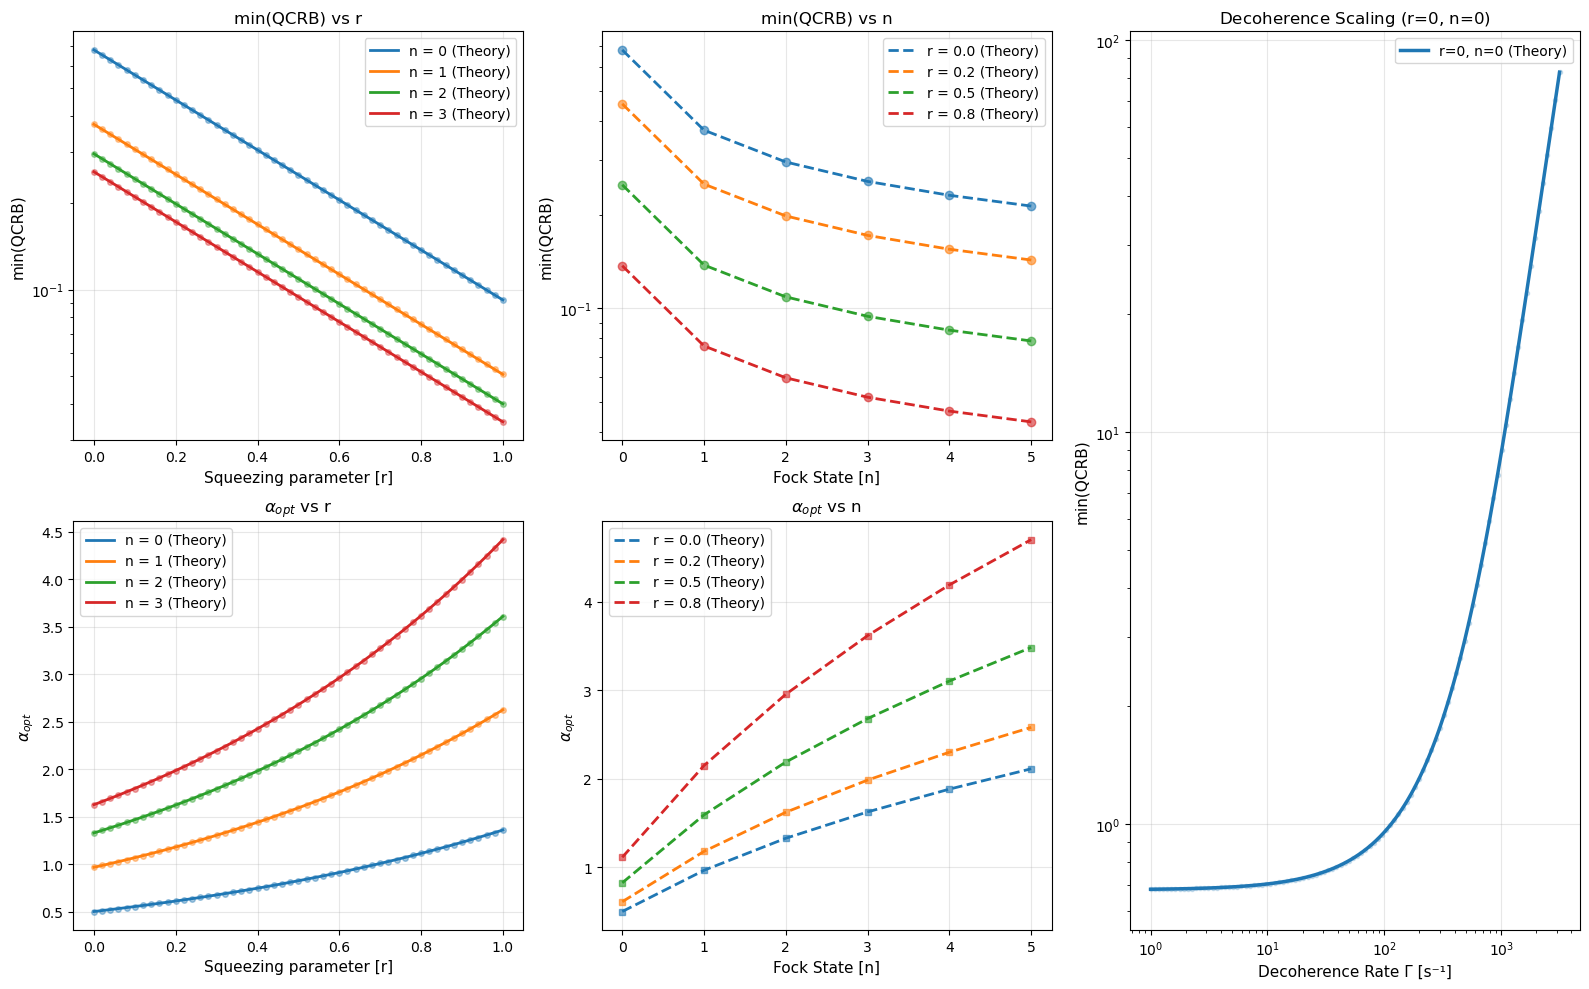

In [19]:
plot_whiteboard_analysis(1e2, 0.0, 0.0)

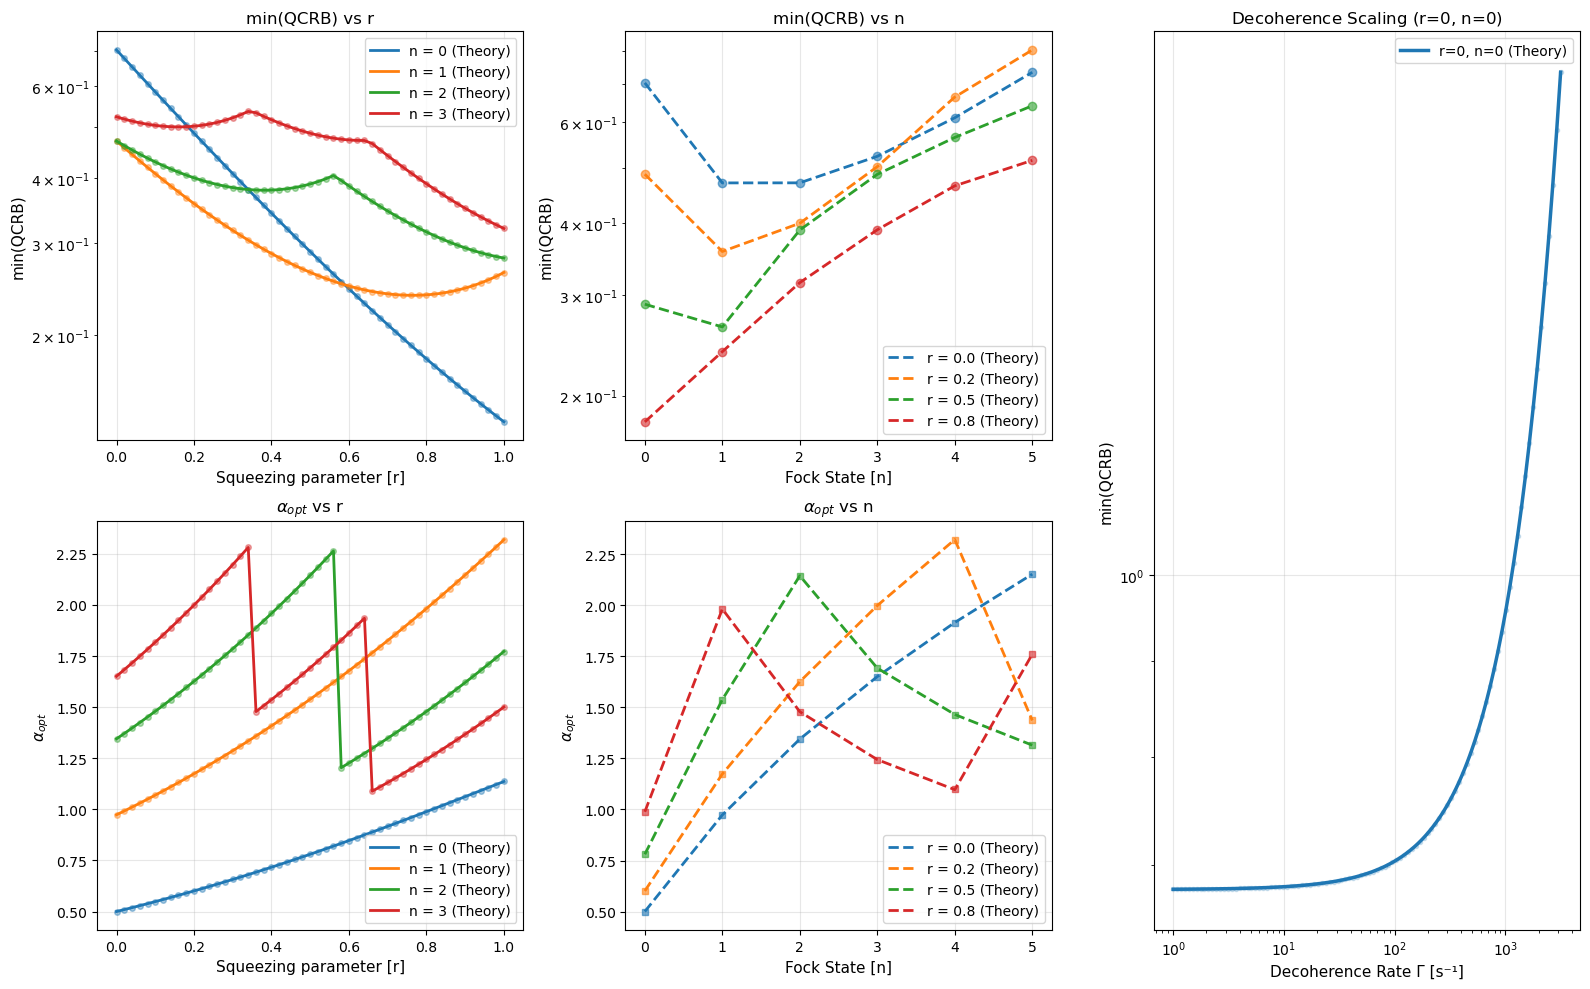

In [20]:
plot_whiteboard_analysis(1e4, 1e2, 0.0)

In [21]:
using PyPlot
using QuantumOptics
using IonSim

# -------------------------------------------------------------
# 1. Helper: Laguerre Polynomials
# -------------------------------------------------------------
function laguerre(n::Int, x::Float64)
    if n == 0 return 1.0 end
    if n == 1 return 1.0 - x end
    L_prev2 = 1.0
    L_prev1 = 1.0 - x
    L_curr = 0.0
    for k in 1:(n-1)
        L_curr = ((2k + 1 - x) * L_prev1 - k * L_prev2) / (k + 1)
        L_prev2 = L_prev1
        L_prev1 = L_curr
    end
    return L_curr
end

# -------------------------------------------------------------
# 2. Helper: Theoretical QCRB Evaluator (Eq. 65 / 74)
# -------------------------------------------------------------
function eval_qcrb_theory(a::Float64, n_fock::Int, r_squeeze::Float64, Gamma_t::Float64, n_th_set::Float64)
    thermal_factor = (2.0 * n_th_set) + 1.0
    B_var = thermal_factor * (1.0 - exp(-Gamma_t)) + exp(-Gamma_t - 2.0 * r_squeeze)
    numerator = exp(4.0 * a^2 * B_var)
    L_val = laguerre(n_fock, 4.0 * a^2 * exp(-Gamma_t - 2.0 * r_squeeze))
    continuous_signal = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0
    denominator = 16.0 * a^2 * (continuous_signal^2) * (L_val^2)
    return denominator <= 1e-14 ? Inf : numerator / denominator
end

# -------------------------------------------------------------
# 3. Helper: Characteristic Equation & Roots (Eq. 85)
# -------------------------------------------------------------
function open_characteristic_equation(y::Float64, n::Int, gamma_eff::Float64)
    if y <= 0.0 return 1.0 end
    δ = 1.0e-5
    Ln = laguerre(n, y)
    Ln_p = laguerre(n, y + δ)
    Ln_m = laguerre(n, y - δ)
    dL_dy = (Ln_p - Ln_m) / (2.0 * δ)
    return Ln - gamma_eff * y * Ln + 2.0 * y * dL_dy
end

function get_characteristic_roots(n_fock::Int, gamma_eff::Float64)
    y_grid = range(0.01, stop=50.0, length=4000)
    roots = Float64[]
    for i in 1:(length(y_grid)-1)
        y1 = y_grid[i]; y2 = y_grid[i+1]
        f1 = open_characteristic_equation(y1, n_fock, gamma_eff)
        f2 = open_characteristic_equation(y2, n_fock, gamma_eff)
        if f1 * f2 <= 0.0
            a_b = y1; b_b = y2
            for _ in 1:20
                mid = 0.5 * (a_b + b_b)
                if open_characteristic_equation(a_b, n_fock, gamma_eff) * open_characteristic_equation(mid, n_fock, gamma_eff) <= 0.0
                    b_b = mid
                else
                    a_b = mid
                end
            end
            push!(roots, 0.5 * (a_b + b_b))
        end
    end
    return roots
end

# -------------------------------------------------------------
# 4. NEW: Exact Closed-System Trendline Calculator
# -------------------------------------------------------------
function get_exact_closed_trendline(n_fock::Int, r_squeeze::Float64)
    if n_fock == 0
        y_opt = 1.0
    else
        # Find exact ideal root by enforcing a closed system (gamma_eff = 1.0)
        ideal_roots = get_characteristic_roots(n_fock, 1.0)
        best_y = 1.0
        best_qcrb_metric = Inf
        for y_rt in ideal_roots
            if y_rt > 0.0
                L_val = laguerre(n_fock, y_rt)
                qcrb_val = 1.0 / (y_rt * exp(-y_rt) * L_val^2)
                if qcrb_val < best_qcrb_metric
                    best_qcrb_metric = qcrb_val
                    best_y = y_rt
                end
            end
        end
        y_opt = best_y
    end
    
    # 1. Exact Alpha Trendline: C_n * exp(r) (Eq. 80)
    alpha_trend = (sqrt(y_opt) / 2.0) * exp(r_squeeze)
    
    # 2. Exact QCRB Trendline: K_n * exp(-2r) (Eq. 77 inverse)
    L_val = laguerre(n_fock, y_opt)
    qcrb_trend = 1.0 / (4.0 * y_opt * exp(2.0 * r_squeeze) * exp(-y_opt) * L_val^2)
    
    return alpha_trend, qcrb_trend
end

# -------------------------------------------------------------
# 5. Solver for Open System (Sweep + Theory)
# -------------------------------------------------------------
function get_optimal_point(n_fock::Int, r_squeeze::Float64, Gamma_t::Float64, n_th_set::Float64)
    thermal_factor = (2.0 * n_th_set) + 1.0
    B_var = thermal_factor * (1.0 - exp(-Gamma_t)) + exp(-Gamma_t - 2.0 * r_squeeze)
    continuous_signal = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0

    if n_fock == 0
        opt_alpha = 1.0 / (2.0 * sqrt(B_var))
        min_qcrb = (exp(1.0) * B_var) / (4.0 * continuous_signal^2)
        return opt_alpha, min_qcrb, opt_alpha, min_qcrb
    end

    # --- METHOD A: Dense Sweep ---
    alpha_max = 3.0 * exp(r_squeeze + Gamma_t / 2.0)
    alpha_grid = range(0.05, stop=alpha_max, length=3000)
    best_qcrb_sweep = Inf; best_alpha_sweep = 0.05
    for a in alpha_grid
        val = eval_qcrb_theory(a, n_fock, r_squeeze, Gamma_t, n_th_set)
        if val < best_qcrb_sweep; best_qcrb_sweep = val; best_alpha_sweep = a; end
    end

    # --- METHOD B: Open Theory Roots (With Pikes) ---
    gamma_eff = 1.0 + exp(2.0 * r_squeeze) * (exp(Gamma_t) - 1.0)
    open_roots = get_characteristic_roots(n_fock, gamma_eff)
    best_qcrb_theory = Inf; best_alpha_theory = best_alpha_sweep
    
    if !isempty(open_roots)
        for y_rt in open_roots
            if y_rt > 0.0
                a_candidate = (sqrt(y_rt) / 2.0) * exp(Gamma_t / 2.0 + r_squeeze)
                val = eval_qcrb_theory(a_candidate, n_fock, r_squeeze, Gamma_t, n_th_set)
                if val < best_qcrb_theory && isfinite(val)
                    best_qcrb_theory = val; best_alpha_theory = a_candidate
                end
            end
        end
    else
        best_qcrb_theory = best_qcrb_sweep
    end

    return best_alpha_sweep, best_qcrb_sweep, best_alpha_theory, best_qcrb_theory
end

# -------------------------------------------------------------
# 6. Master Whiteboard Plotter
# -------------------------------------------------------------
function plot_whiteboard_analysis(laser_intensity::Float64=1e3, gamma_0::Float64=1e2, n_th_set::Float64=0.0)
    trap_freq = 19e5; hbar = 1.0545718e-34; amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    
    eta = (2 * π / transition_λ / sqrt(2)) * sqrt(hbar / (2 * m_Ca40 * 2 * π * trap_freq))
    dummy_laser = Laser(I=laser_intensity, k=(x̂ + ẑ)/√2, ϵ=ŷ, λ=transition_λ)
    Omega_eff = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0)) * 2 * π
    
    t_sig_us = ((2.0 * 1.0) / (eta * Omega_eff)) * 1e6
    Gamma_t = (gamma_0 * 1e-6) * t_sig_us

    r_vals = collect(0.0:0.02:1.0); n_vals = [0, 1, 2, 3]
    fig = figure(figsize=(18, 10))

    # --- Plot 1: min(QCRB) vs r ---
    subplot(2, 3, 1)
    for n in n_vals
        results_open = [get_optimal_point(n, r, Gamma_t, n_th_set) for r in r_vals]
        results_ideal = [get_exact_closed_trendline(n, r) for r in r_vals]
        
        q_min_sweep = [res[2] for res in results_open]
        q_min_theory = [res[4] for res in results_open]
        q_min_ideal = [res[2] for res in results_ideal]
        
        # Explicitly label both lines with the parameter 'n'
        p = plot(r_vals, q_min_theory, "-", linewidth=2, label="n = $n (Open)")
        c = p[1].get_color()
        plot(r_vals, q_min_ideal, ":", color=c, linewidth=2.5, alpha=0.8, label="n = $n (Closed)") 
        plot(r_vals, q_min_sweep, "o", color=c, alpha=0.3, markersize=3)
    end
    yscale("log"); xlabel("Squeezing parameter [r]", fontsize=11); ylabel("min(QCRB)", fontsize=11)
    title("min(QCRB) vs r", fontsize=12); grid(alpha=0.3); legend(fontsize=9)

    # --- Plot 2: min(QCRB) vs n ---
    subplot(2, 3, 2)
    r_targets = [0.0, 0.2, 0.5, 0.8]; n_dense = 0:5
    for r in r_targets
        results_open = [get_optimal_point(n, r, Gamma_t, n_th_set) for n in n_dense]
        results_ideal = [get_exact_closed_trendline(n, r) for n in n_dense]
        
        q_min_sweep_n = [res[2] for res in results_open]
        q_min_theory_n = [res[4] for res in results_open]
        q_min_ideal_n = [res[2] for res in results_ideal]
        
        # Explicitly label both lines with the parameter 'r'
        p = plot(n_dense, q_min_theory_n, "--", linewidth=2, label="r = $r (Open)")
        c = p[1].get_color()
        plot(n_dense, q_min_ideal_n, ":", color=c, linewidth=2.5, alpha=0.8, label="r = $r (Closed)")
        plot(n_dense, q_min_sweep_n, "o", color=c, alpha=0.5, markersize=6)
    end
    yscale("log"); xlabel("Fock State [n]", fontsize=11); ylabel("min(QCRB)", fontsize=11)
    title("min(QCRB) vs n", fontsize=12); grid(alpha=0.3); legend(fontsize=9)

    # --- Plot 3: opt α vs r ---
    subplot(2, 3, 4)
    for n in n_vals
        results_open = [get_optimal_point(n, r, Gamma_t, n_th_set) for r in r_vals]
        results_ideal = [get_exact_closed_trendline(n, r) for r in r_vals]
        
        alpha_sweep = [res[1] for res in results_open]
        alpha_theory = [res[3] for res in results_open]
        alpha_ideal = [res[1] for res in results_ideal]
        
        p = plot(r_vals, alpha_theory, "-", linewidth=2, label="n = $n (Open)")
        c = p[1].get_color()
        plot(r_vals, alpha_ideal, ":", color=c, linewidth=2.5, alpha=0.8, label="n = $n (Closed)")
        plot(r_vals, alpha_sweep, "o", color=c, alpha=0.3, markersize=3)
    end
    xlabel("Squeezing parameter [r]", fontsize=11); ylabel(L"\alpha_{opt}", fontsize=11)
    title(L"\alpha_{opt}\text{ vs r}", fontsize=12); grid(alpha=0.3); legend(fontsize=9)

    # --- Plot 4: opt α vs n ---
    subplot(2, 3, 5)
    for r in r_targets
        results_open = [get_optimal_point(n, r, Gamma_t, n_th_set) for n in n_dense]
        results_ideal = [get_exact_closed_trendline(n, r) for n in n_dense]
        
        alpha_sweep_n = [res[1] for res in results_open]
        alpha_theory_n = [res[3] for res in results_open]
        alpha_ideal_n = [res[1] for res in results_ideal]
        
        p = plot(n_dense, alpha_theory_n, "--", linewidth=2, label="r = $r (Open)")
        c = p[1].get_color()
        plot(n_dense, alpha_ideal_n, ":", color=c, linewidth=2.5, alpha=0.8, label="r = $r (Closed)")
        plot(n_dense, alpha_sweep_n, "s", color=c, alpha=0.5, markersize=5)
    end
    xlabel("Fock State [n]", fontsize=11); ylabel(L"\alpha_{opt}", fontsize=11)
    title(L"\alpha_{opt}\text{ vs n}", fontsize=12); grid(alpha=0.3); legend(fontsize=9)

    # --- Plot 5: min(QCRB) vs Decoherence Rate Γ ---
    subplot(1, 3, 3)
    gamma_sweep = 10.0 .^ range(0.0, 3.5, length=100)
    
    
    # Ideal line for n=0, r=0 is constant w.r.t gamma_0
    _, ideal_qcrb_val = get_exact_closed_trendline(0, 0.0)
    
    for r in r_targets

        for n in n_vals
            q_gamma_theory = Float64[]; q_gamma_sweep = Float64[]; q_gamma_ideal = Float64[]

    for g_val in gamma_sweep
        gt_local = (g_val * 1e-6) * t_sig_us
        res = get_optimal_point(n, r, gt_local, n_th_set)
        push!(q_gamma_sweep, res[2])
        push!(q_gamma_theory, res[4])
        push!(q_gamma_ideal, ideal_qcrb_val)
    end
   p = plot(gamma_sweep, q_gamma_theory, "-", linewidth=2.5, label="r=$r, n=$n (Open)")
    c = p[1].get_color()
    plot(gamma_sweep, q_gamma_ideal, ":", color=c, linewidth=2.5, label="r=$r, n=$n (Closed)")
    plot(gamma_sweep, q_gamma_sweep, "o", color=c, alpha=0.2, markersize=3)
    
end
end

    
 
    
    xscale("log"); yscale("log")
    xlabel("Decoherence Rate Γ [s⁻¹]", fontsize=11); ylabel("min(QCRB)", fontsize=11)
    title(L"\text{Decoherence Scaling (r, n)}", fontsize=12)
    grid(alpha=0.3); legend(bbox_to_anchor=(1.05, 0.0),fontsize=9, loc = "lower center")

    tight_layout()
    display(fig)
end

plot_whiteboard_analysis (generic function with 4 methods)

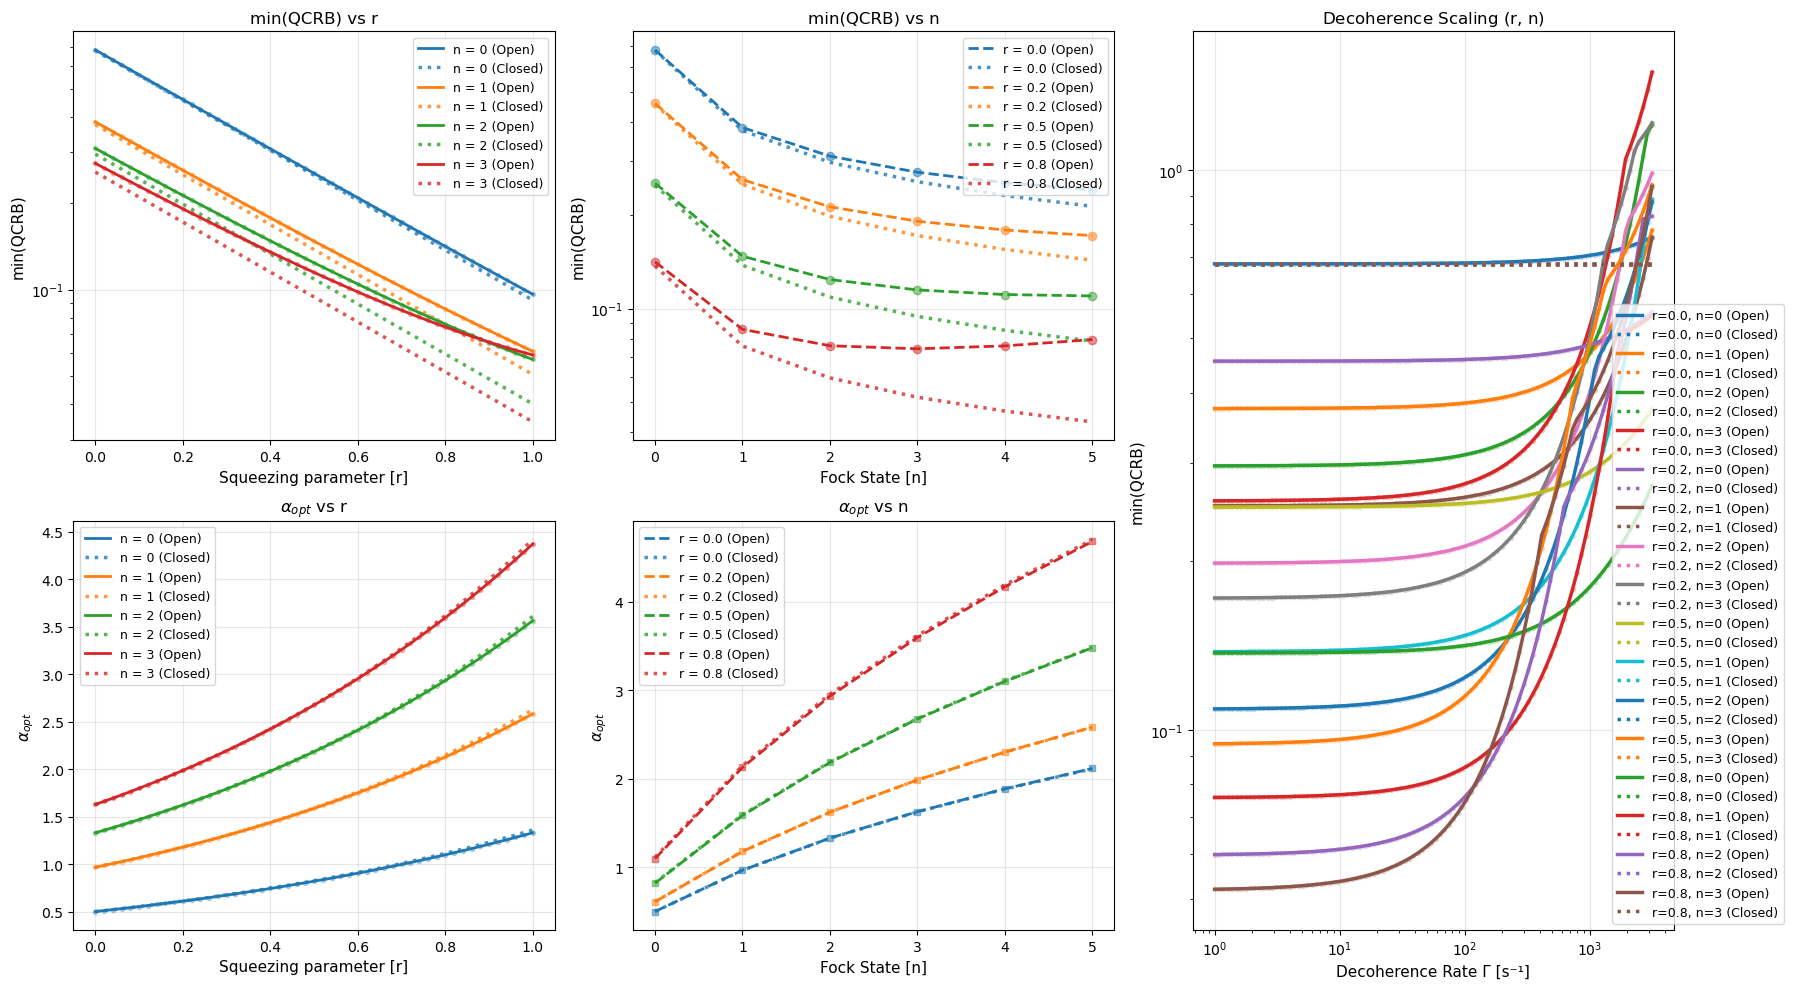

In [22]:
plot_whiteboard_analysis(1e6, 1e2, 0.0)

In [67]:
function plot_wigner(final_state)
    rho_motional = ptrace(final_state, 1)

b_fock = FockBasis(50)
rho_fock = DenseOperator(b_fock, rho_motional.data)

x_vec = -4.0:0.1:4.0
p_vec = -4.0:0.1:4.0

W = wigner(rho_fock, x_vec, p_vec)

fig = figure(figsize=(8, 6))
PyPlot.pcolormesh(x_vec, p_vec, W, cmap="RdBu_r", vmin=-0.3, vmax=0.3, shading="nearest")
PyPlot.colorbar(label="Wigner Function W(x, p)")

# Add a marker where the vacuum state (0,0) originally was
PyPlot.plot([0], [0], "w+", markersize=15, markeredgewidth=2, label="Original Vacuum |0>")

PyPlot.xlabel("Position (x)")
PyPlot.ylabel("Momentum (p)")
PyPlot.title("Displaced Motional State")
PyPlot.legend()
PyPlot.grid(color="white", alpha=0.2)

# Display the figure safely in Jupyter (removed show() to prevent the device warning)
display(fig)
end

plot_wigner (generic function with 1 method)

In [68]:
testde = SDF_apply_with_alpha_dephasing(1e4, pi/2, 0.716, false, nothing, 1,  1e3)

Simulating continuous Beta displacement with Pure Dephasing...


Operator(dim=102x102)
  basis: [⁴⁰Ca ⊗ VibrationalMode(ν=1.9e6, axis=ẑ, N=50)]
    0.288677+0.0im          0.0+0.0im  …  1.68083e-11+0.0im         0.0+0.0im
         0.0+0.0im          0.0+0.0im             0.0+0.0im         0.0+0.0im
    -1.0e-17-0.204279im     0.0+0.0im             0.0-3.4833e-13im  0.0+0.0im
         0.0+0.0im          0.0+0.0im             0.0+0.0im         0.0+0.0im
    0.199983-2.0e-17im      0.0+0.0im       -5.16e-15-0.0im         0.0+0.0im
         0.0+0.0im          0.0+0.0im  …          0.0+0.0im         0.0+0.0im
     1.0e-17+0.0774144im    0.0+0.0im            -0.0+6.0e-17im     0.0+0.0im
         0.0+0.0im          0.0+0.0im             0.0+0.0im         0.0+0.0im
  -0.0187361+0.0im          0.0+0.0im             0.0+0.0im         0.0+0.0im
         0.0+0.0im          0.0+0.0im             0.0+0.0im         0.0+0.0im
            ⋮                          ⋱             ⋮              
         0.0+0.0im          0.0+0.0im             0.0+0.0im         0.0

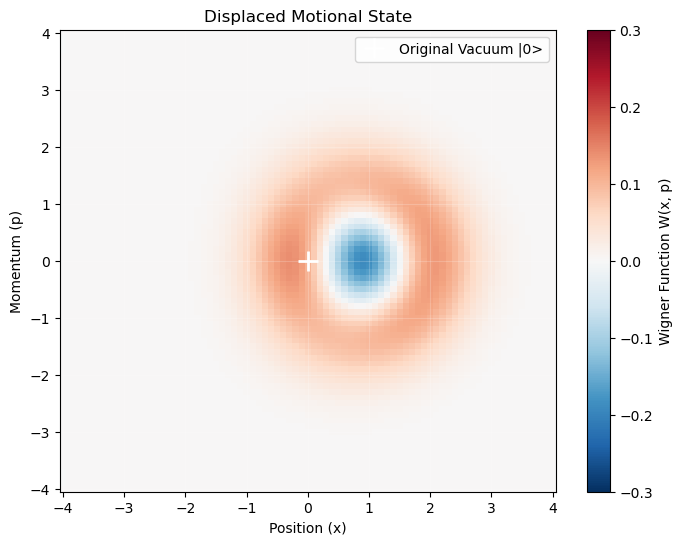

In [69]:
plot_wigner(testde)

In [84]:
function SDF_apply_with_alpha_dephasing(laser_intensity = 1e4, angle = 0, target_alpha = 0.716, cat_state = false, initial_state = nothing, fock_state_n = 0, gamma_phi_set = 1e-2)
    # 1. Common Trap Initialization
    trap_freq = 19e5 
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    
    mode_z = zmodes(chain)[1] 
    mode_z.N = 50
    mode_z.shape = [51]
    
    k_vec = (x̂ + ẑ) / √2
    ϵ_vec = ŷ
    B_field = 1e-13
    
    trap_pre = Chamber(iontrap=chain, B=B_field, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    mode = zmodes(trap_pre)[1]
    
    ψ_ion = normalize(ion["g"])
    ψ_mode = fockstate(mode, fock_state_n)
    ψ_initial = initial_state !== nothing ? initial_state : (ψ_ion ⊗ ψ_mode)

    # 2. Physics Calculation
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_total = 2 * π / transition_λ
    k_z = k_total / sqrt(2)
    eta = k_z * z_zpf

    dummy_laser = Laser(I=laser_intensity, k=k_vec, ϵ=ϵ_vec, λ=transition_λ)
    Bhat_tuple = (; x=0.0, y=0.0, z=1.0)
    
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), Bhat_tuple)
    Omega_eff = Omega_eff_Hz * 2 * π

    # 3. SEQUENCE EXECUTION
    if cat_state
        # PERFECT OPERATOR MATH: Alpha Readout (No readout noise)
        alpha_complex = target_alpha * exp(1im * angle)
        g = ion["g"]
        e = ion["e"]
        
        x_plus = normalize(g + e)
        x_minus = normalize(g - e)
        
        P_plus = x_plus ⊗ dagger(x_plus)
        P_minus = x_minus ⊗ dagger(x_minus)
        
        D_plus = IonSim.displace(mode, alpha_complex)
        D_minus = IonSim.displace(mode, -alpha_complex)
        
        U_SDF = (P_plus ⊗ D_plus) + (P_minus ⊗ D_minus)
        
        if isa(ψ_initial, Operator)
            return U_SDF * ψ_initial * dagger(U_SDF)
        else
            return U_SDF * ψ_initial
        end
        
    else
        # CONTINUOUS LINDBLAD DISPLACEMENT: Beta Signal (PURE DEPHASING)
        I_spin = identityoperator(ion["g"].basis)  
        gamma_phi_us = gamma_phi_set * 1e-6 

        temp_fock_basis = FockBasis(mode.N) 
        a_op = DenseOperator(mode, mode, QuantumOptics.destroy(temp_fock_basis).data)
        at_op = DenseOperator(mode, mode, QuantumOptics.create(temp_fock_basis).data)
        
        # PURE DEPHASING GENERATOR: Number operator n = a^dag a
        n_op = DenseOperator(mode, mode, QuantumOptics.number(temp_fock_basis).data)

        baseline_beta = 1.0 
        target_time_s = (2 * baseline_beta) / (eta * Omega_eff)
        target_time_us = target_time_s * 1e6

        H_m = (1im * target_alpha / target_time_us) * (exp(1im * angle) * at_op - exp(-1im * angle) * a_op)
        H_sys = I_spin ⊗ H_m

        n_sys = I_spin ⊗ n_op

        # PURE DEPHASING JUMP OPERATOR
        J_dephase = sqrt(gamma_phi_us) * n_sys
        J_ops = [J_dephase]
        J_ops_dag = dagger.(J_ops)

        function f_dyn(time_t, rho_state)
            return (H_sys, J_ops, J_ops_dag)
        end

        rho_initial = isa(ψ_initial, Ket) ? dm(ψ_initial) : ψ_initial
        tspan_sdf = [0.0, target_time_us]

        println("Simulating continuous Beta displacement with Pure Dephasing...")
        _, sol_beta = timeevolution.master_dynamic(tspan_sdf, rho_initial, f_dyn, reltol=1e-10, abstol=1e-12)

        return sol_beta[end]
    end
end

function get_qcrb_coordinates_dephasing(n_fock::Int=0, laser_intensity::Float64=1e3, gamma_phi::Float64=1e-2)
    beta_signal = 1.0
    d_beta = 1e-4 
    
    # ... trap calculations identical to original ...
    trap_freq = 19e5 
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    B_field = 1e-13
    trap_pre = Chamber(iontrap=chain, B=B_field, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    sim_mode = zmodes(trap_pre)[1]
    sim_mode.N = 50
    sim_mode.shape = [51]

    b_fock = FockBasis(50) 
    vac_qo = fockstate(b_fock, n_fock)
    
    # Enforce NO SQUEEZING for Dephasing
    initial_m_qo = vac_qo
    
    initial_m_sim = Ket(sim_mode, initial_m_qo.data)
    initial_sys = normalize(ion["g"]) ⊗ initial_m_sim

    println("\nRunning master equation for Base β Signal...")
    noisy_beta_state = SDF_apply_with_alpha_dephasing(laser_intensity, 0.0, beta_signal, false, initial_sys, n_fock, gamma_phi)
    
    println("\nRunning master equation for Perturbed β Signal (+ d_beta)...")
    noisy_beta_state_pert = SDF_apply_with_alpha_dephasing(laser_intensity, 0.0, beta_signal + d_beta, false, initial_sys, n_fock, gamma_phi)

    alphas = collect(0.1:0.05:1.6)
    sim_qcrbs = Float64[]
    theory_closed_qcrbs = Float64[]

    println("\nSweeping α readout (generating coordinates)...")
    for a in alphas
        state_a_full = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, noisy_beta_state, n_fock, gamma_phi)
        state_a_pert_full = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, noisy_beta_state_pert, n_fock, gamma_phi)

        rho_spin_a = ptrace(state_a_full, 2)
        rho_spin_a_pert = ptrace(state_a_pert_full, 2)
        
        _, qcrb_sim = calculate_qcrb(rho_spin_a, rho_spin_a_pert, d_beta)
        push!(sim_qcrbs, qcrb_sim)

        # CLOSED SYSTEM BASELINE (No squeezing)
        exp_term_closed = 4 * a^2 
        numerator_closed = exp(exp_term_closed)
        L_val_closed = laguerre(n_fock, 4 * a^2)
        denominator_closed = 16 * a^2 * (L_val_closed^2)
        
        push!(theory_closed_qcrbs, numerator_closed / denominator_closed)
    end

    return alphas, sim_qcrbs, theory_closed_qcrbs
end

function plot_qcrb_results_dephasing(n_fock::Int=0, laser_intensity::Float64=1e3, gamma_phi::Float64=1e-2)
    x_alpha, y_sim, y_theory_closed = get_qcrb_coordinates_dephasing(n_fock, laser_intensity, gamma_phi)

    # Recompute coupling rate g
    trap_freq = 19e5; hbar = 1.0545718e-34; amu = 1.66053906e-27; m_Ca40 = 39.96259 * amu    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_z = (2 * π / transition_λ) / sqrt(2)
    eta = k_z * z_zpf
    
    k_vec = (x̂ + ẑ) / √2; ϵ_vec = ŷ
    dummy_laser = Laser(I=laser_intensity, k=k_vec, ϵ=ϵ_vec, λ=transition_λ)
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0))
    g_display = round((eta * Omega_eff_Hz * 2 * π) / 2.0, digits=2)

    fig = figure(figsize=(8, 6))
    
    plot(x_alpha, y_sim, "o-", markersize=8, color="dodgerblue", linewidth=2.5, label="Simulation (Pure Dephasing)")
    plot(x_alpha, y_theory_closed, "r:", linewidth=2, label="Theory (Eq. 33: Ideal Closed System)")

    yscale("log")
    xlabel("Readout Displacement [α]", fontsize=12)
    ylabel("QCRB (Ancilla Measurement Limit)", fontsize=12)
    
    title("Dephasing: Fock = $(n_fock) (No Squeezing), I = $(laser_intensity) (g = $(g_display)), Γ_ϕ = $(gamma_phi)", fontsize=11)
    
    legend(fontsize=11)
    grid(alpha=0.4)
    
    display(fig)
end

plot_qcrb_results_dephasing (generic function with 4 methods)


Running master equation for Base β Signal...
Simulating continuous Beta displacement with Pure Dephasing...

Running master equation for Perturbed β Signal (+ d_beta)...
Simulating continuous Beta displacement with Pure Dephasing...

Sweeping α readout (generating coordinates)...


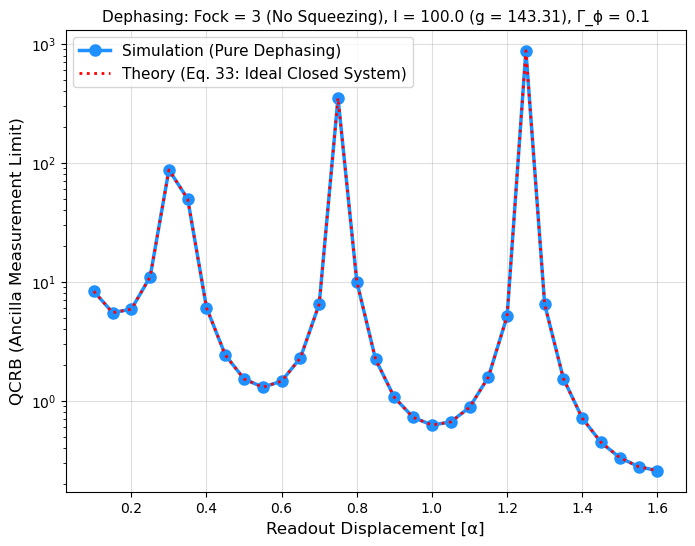

In [85]:
plot_qcrb_results_dephasing(3, 1e2, 1e-1)


Running master equation for Base β Signal...
Simulating continuous Beta displacement with Pure Dephasing...

Running master equation for Perturbed β Signal (+ d_beta)...
Simulating continuous Beta displacement with Pure Dephasing...

Sweeping α readout (generating coordinates)...


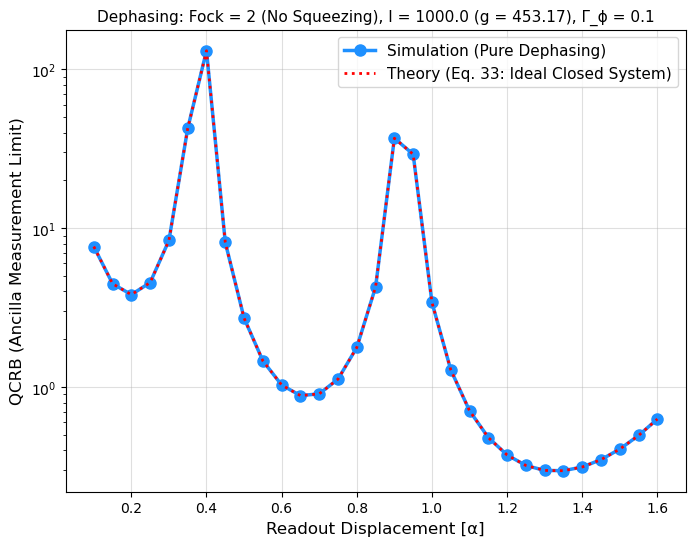

In [86]:
plot_qcrb_results_dephasing(2, 1e3, 1e-1)


Running master equation for Base β Signal...
Simulating continuous Beta displacement with Pure Dephasing...

Running master equation for Perturbed β Signal (+ d_beta)...
Simulating continuous Beta displacement with Pure Dephasing...

Sweeping α readout (generating coordinates)...


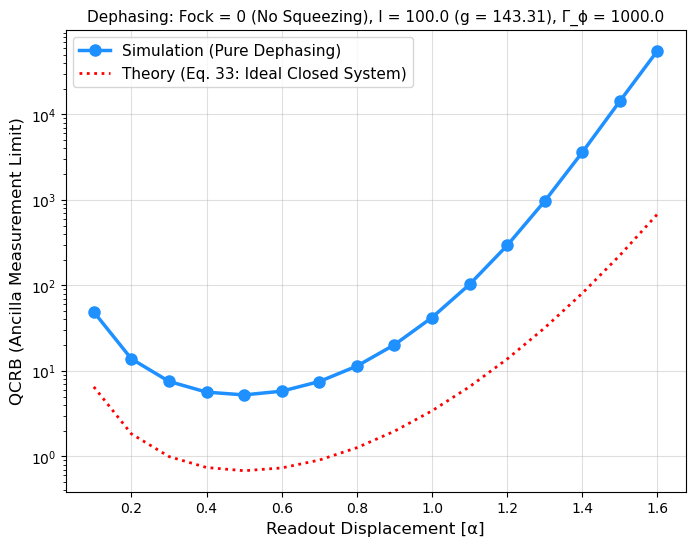

In [28]:
plot_qcrb_results_dephasing(0, 1e2, 1e3)


Running master equation for Base β Signal...
Simulating continuous Beta displacement with Pure Dephasing...

Running master equation for Perturbed β Signal (+ d_beta)...
Simulating continuous Beta displacement with Pure Dephasing...

Sweeping α readout (generating coordinates)...


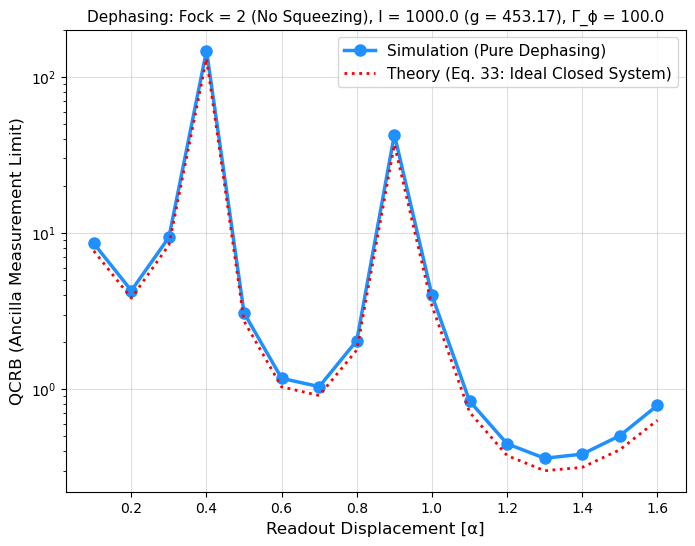

In [29]:
plot_qcrb_results_dephasing(2, 1e3, 1e2)


Running master equation for Base β Signal...
Simulating continuous Beta displacement with Pure Dephasing...

Running master equation for Perturbed β Signal (+ d_beta)...
Simulating continuous Beta displacement with Pure Dephasing...

Sweeping α readout (generating coordinates)...


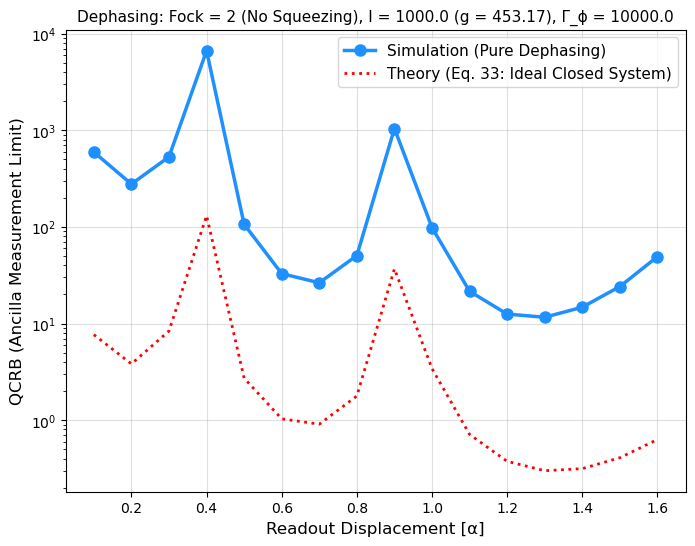

In [30]:
plot_qcrb_results_dephasing(2, 1e3, 1e4)

In [72]:
test_dephase = SDF_apply_with_alpha_dephasing(1e4, pi/2, 1.0 , false, nothing, 0,  0.0)

Simulating continuous Beta displacement with Pure Dephasing...


Operator(dim=102x102)
  basis: [⁴⁰Ca ⊗ VibrationalMode(ν=1.9e6, axis=ẑ, N=50)]
  0.367879-0.0im       0.0+0.0im  …  0.0+0.0im  -0.0-0.0im  0.0+0.0im
       0.0+0.0im       0.0+0.0im     0.0+0.0im   0.0+0.0im  0.0+0.0im
   2.0e-17+0.367879im  0.0+0.0im     0.0+0.0im   0.0-0.0im  0.0+0.0im
       0.0+0.0im       0.0+0.0im     0.0+0.0im   0.0+0.0im  0.0+0.0im
  -0.26013+3.0e-17im   0.0+0.0im     0.0+0.0im   0.0+0.0im  0.0+0.0im
       0.0+0.0im       0.0+0.0im  …  0.0+0.0im   0.0+0.0im  0.0+0.0im
  -3.0e-17-0.150186im  0.0+0.0im     0.0+0.0im  -0.0+0.0im  0.0+0.0im
       0.0+0.0im       0.0+0.0im     0.0+0.0im   0.0+0.0im  0.0+0.0im
 0.0750931-2.0e-17im   0.0+0.0im     0.0+0.0im  -0.0-0.0im  0.0+0.0im
       0.0+0.0im       0.0+0.0im     0.0+0.0im   0.0+0.0im  0.0+0.0im
          ⋮                       ⋱                 ⋮       
       0.0+0.0im       0.0+0.0im     0.0+0.0im   0.0+0.0im  0.0+0.0im
      -0.0-0.0im       0.0+0.0im     0.0+0.0im  -0.0+0.0im  0.0+0.0im
       0.0+0.0im   

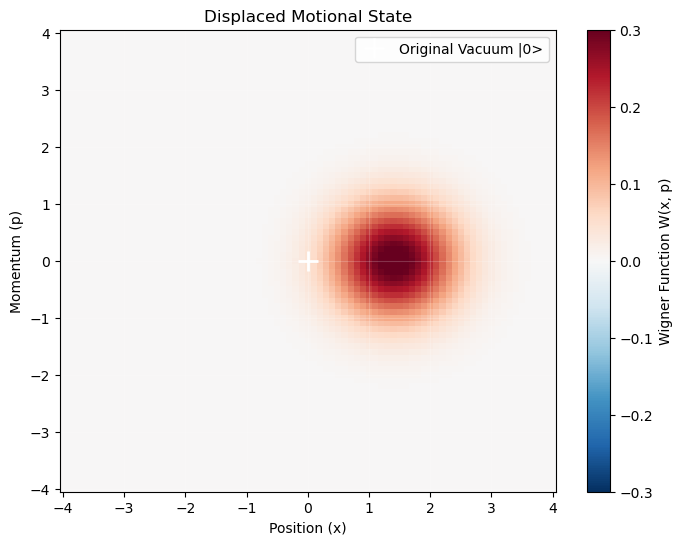

In [73]:
plot_wigner(test_dephase)

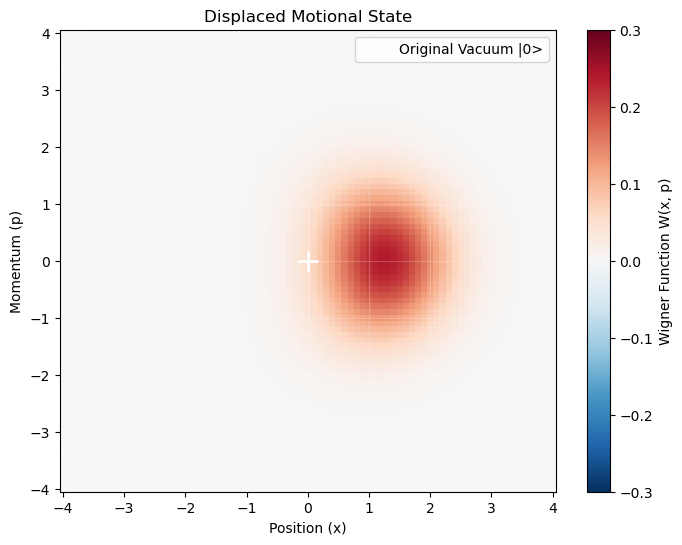

Simulating continuous Beta displacement with Pure Dephasing...


In [74]:
test_dephase = SDF_apply_with_alpha_dephasing(1e4, pi/2, 1.0 , false, nothing, 0,  1e3)
plot_wigner(test_dephase)

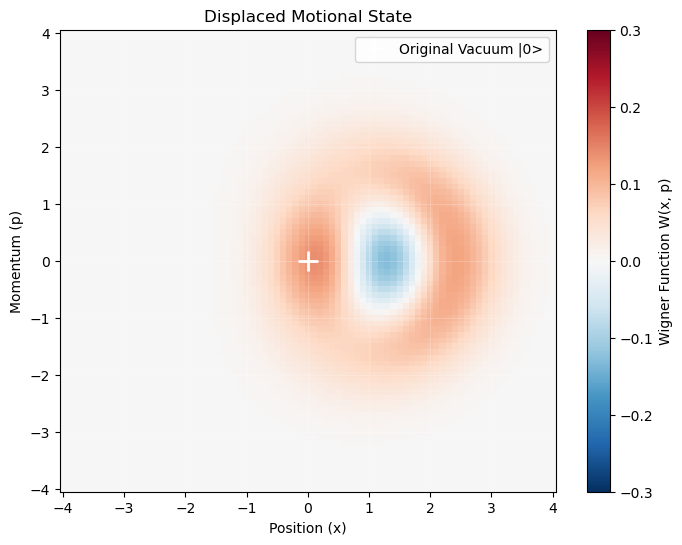

Simulating continuous Beta displacement with Pure Dephasing...


In [75]:
test_dephase = SDF_apply_with_alpha_dephasing(1e4, pi/2, 1.0 , false, nothing, 1,  1e3)
plot_wigner(test_dephase)

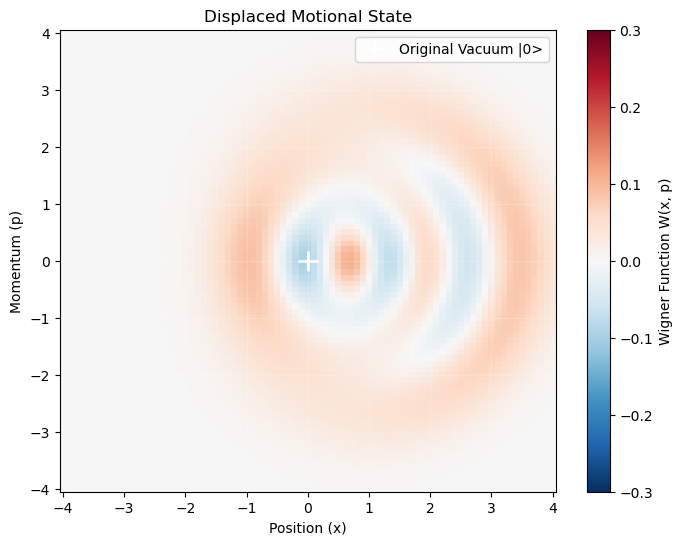

Simulating continuous Beta displacement with Pure Dephasing...


In [76]:
test_dephase = SDF_apply_with_alpha_dephasing(1e4, pi/2, 1.0 , false, nothing, 3,  1e3)
plot_wigner(test_dephase)

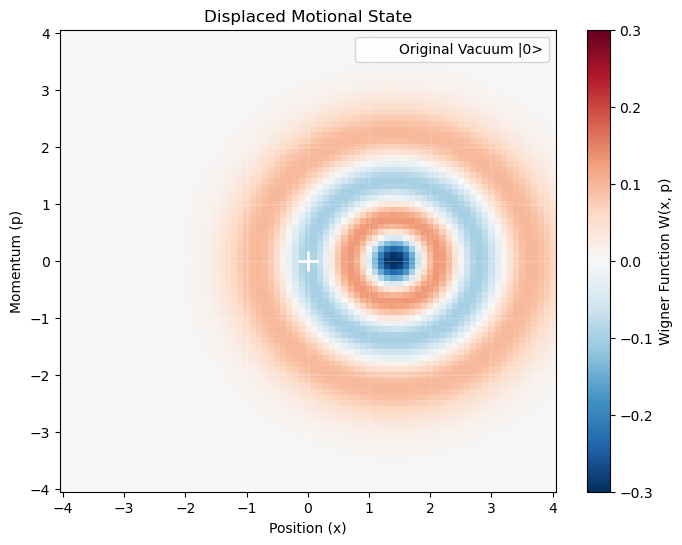

Simulating continuous Beta displacement with Pure Dephasing...


In [77]:
test_dephase = SDF_apply_with_alpha_dephasing(1e4, pi/2, 1.0 , false, nothing, 3,  0.0)
plot_wigner(test_dephase)

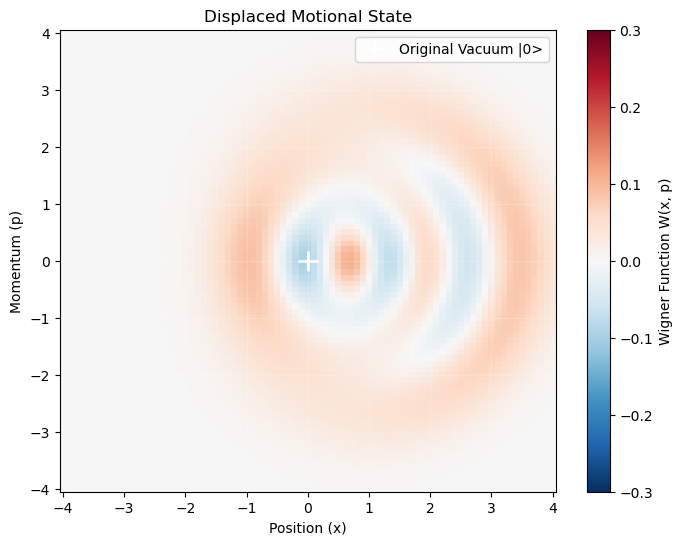

Simulating continuous Beta displacement with Pure Dephasing...


In [81]:
test_dephase = SDF_apply_with_alpha_dephasing(1e4, pi/2, 1.0 , false, nothing, 3,  1000.0)
plot_wigner(test_dephase)


Running master equation for Base β Signal...
Simulating continuous Beta displacement with Pure Dephasing...

Running master equation for Perturbed β Signal (+ d_beta)...
Simulating continuous Beta displacement with Pure Dephasing...

Sweeping α readout (generating coordinates)...


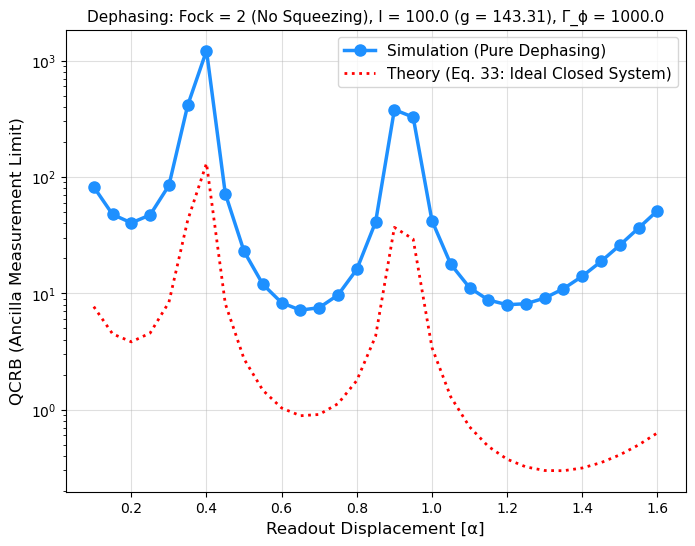

In [90]:
plot_qcrb_results_dephasing(2, 1e2, 1e3)